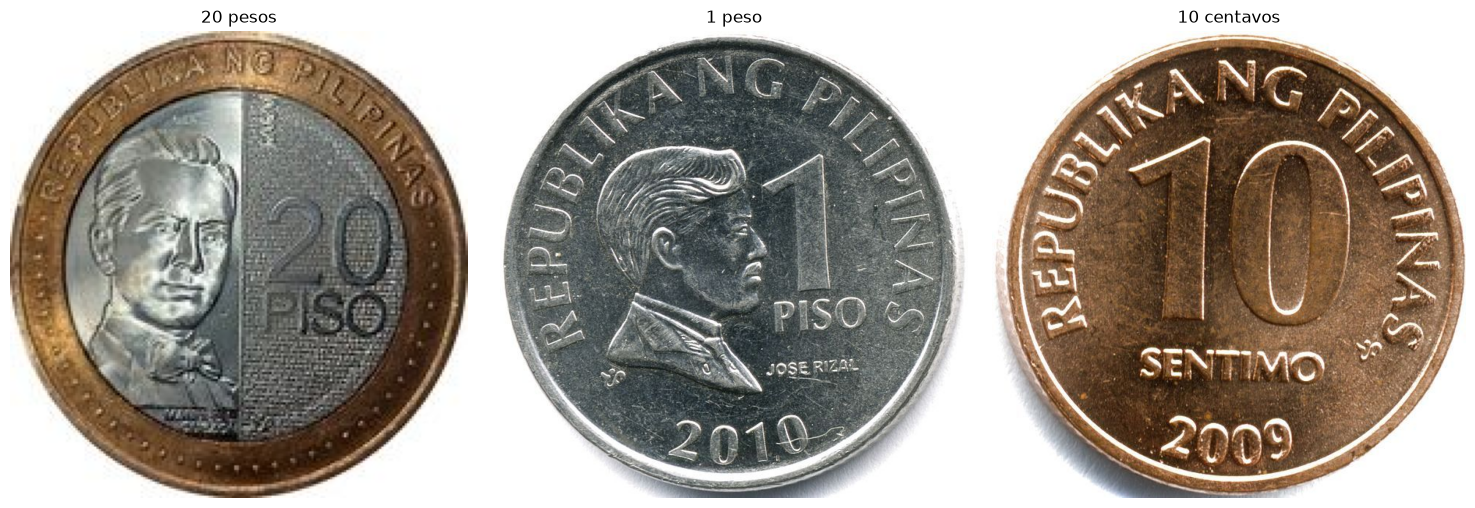

In [37]:
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np
import cv2


# Load the three selected coin images from the dataset
image_folder = Path('coin_images')
selected_images = [
    (image_folder / 'twenty_php.jpg', '20 pesos'),
    (image_folder / 'piso_php.jpeg', '1 peso'),
    (image_folder / 'ten_centavo.jpeg', '10 centavos')
]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, (image_path, label) in zip(axes, selected_images):
    image = Image.open(image_path).convert('RGB')
    ax.imshow(image)
    ax.set_title(label, fontsize=12)
    ax.axis('off')

plt.tight_layout()
plt.show()

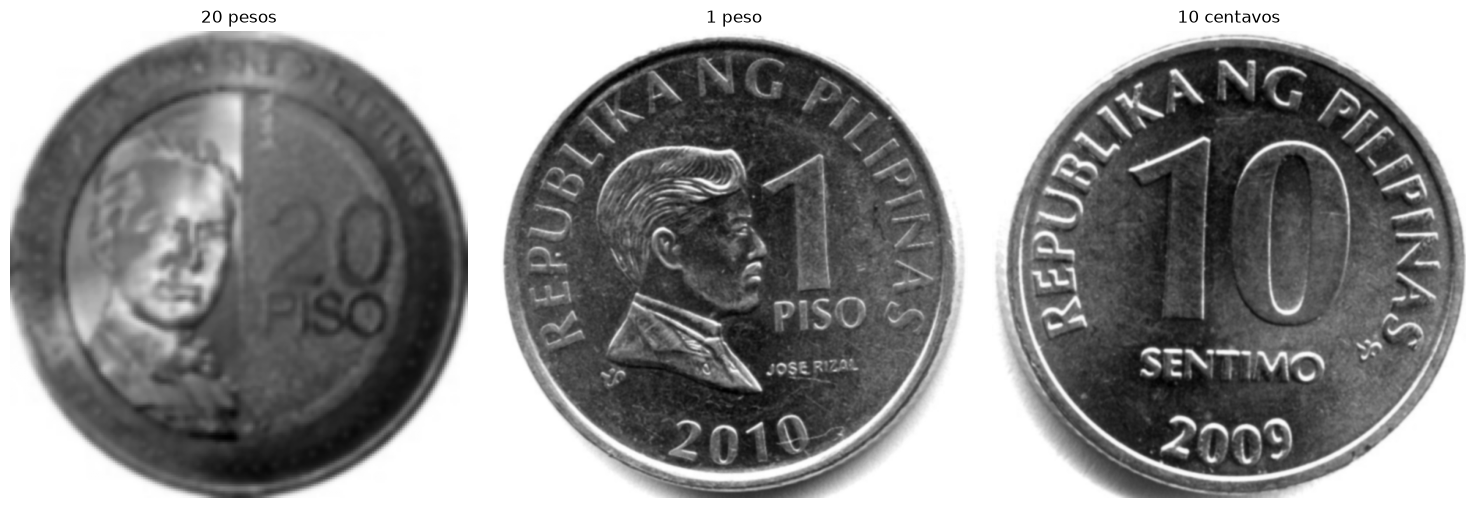

In [38]:
preprocessed_images = []

for item in selected_images:
    image_path = None
    label = None

    if isinstance(item, tuple):
        for element in item:
            if isinstance(element, (str, Path)) and Path(element).exists():
                image_path = Path(element)
                break
        if image_path is None:
            image_path = Path(item[0]) if len(item) > 0 else None
        for element in item:
            if not (isinstance(element, (str, Path)) and Path(element).exists()):
                label = str(element)
                break
    else:
        image_path = Path(item)

    if image_path is None:
        continue

    if label is None:
        label = image_path.stem

    gray_image = Image.open(image_path).convert('L')
    median_image = gray_image.filter(ImageFilter.MedianFilter(size=3))
    blurred_image = median_image.filter(ImageFilter.GaussianBlur(radius=1))
    preprocessed_images.append((label, blurred_image))

# Display the preprocessed images
fig, axes = plt.subplots(1, len(preprocessed_images), figsize=(5 * len(preprocessed_images), 5))

if len(preprocessed_images) == 1:
    axes = [axes]

for ax, (label, image) in zip(axes, preprocessed_images):
    ax.imshow(image, cmap='gray')
    ax.set_title(label)
    ax.axis('off')

plt.tight_layout()
plt.show()

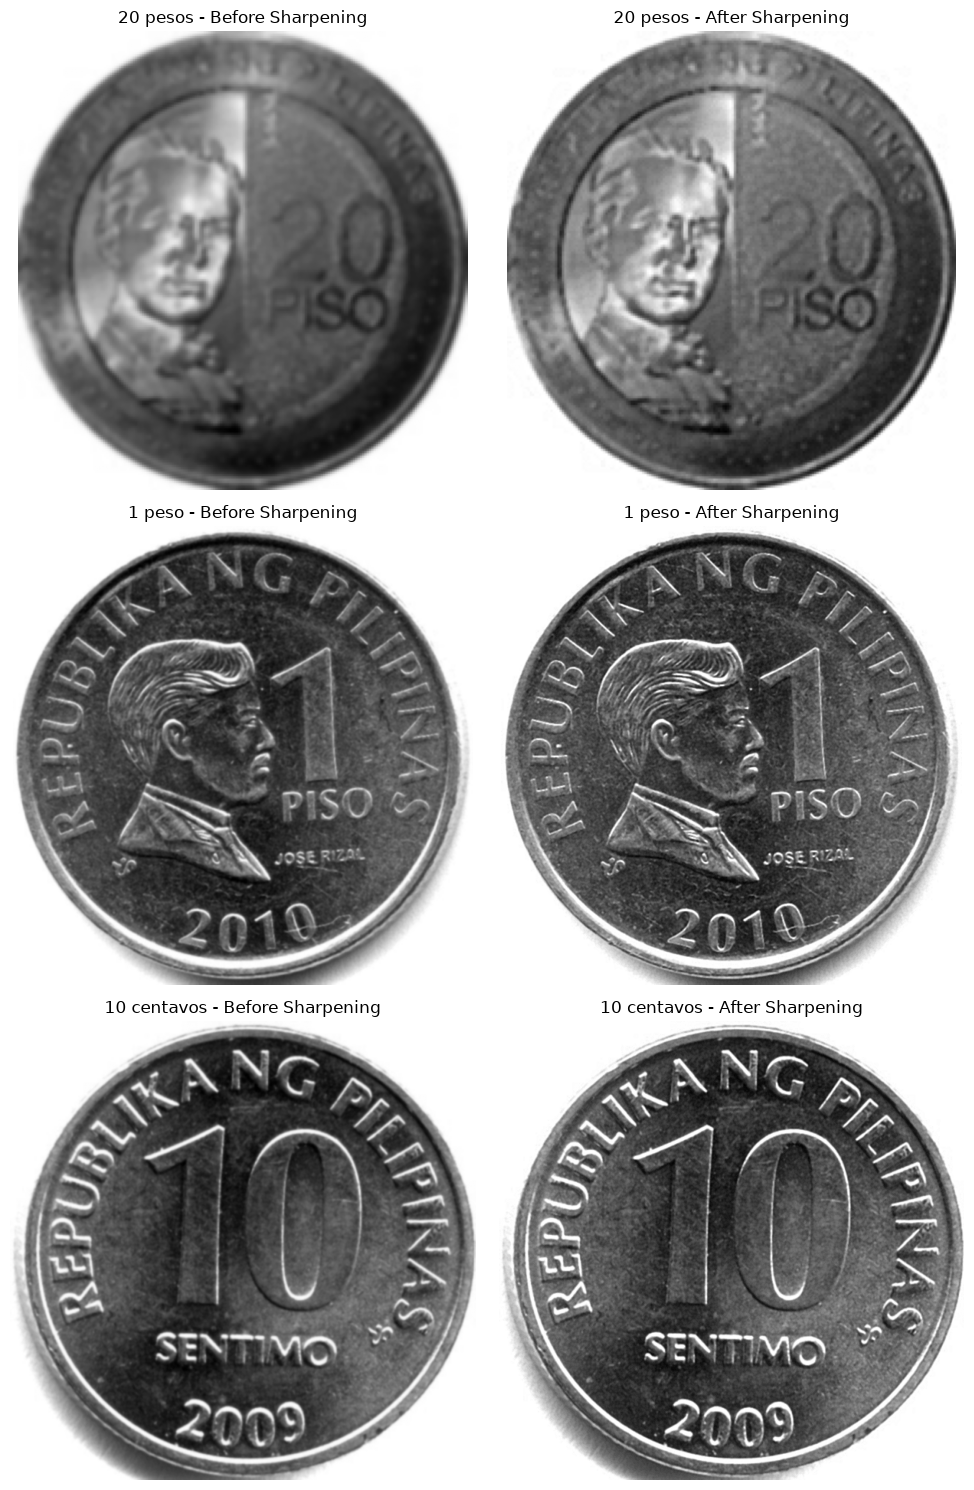

In [39]:
sharpen_kernel = np.array([
    [0, -1, 0],
    [-1, 5, -1],
    [0, -1, 0]
], dtype=np.float32)

def apply_convolution(image, kernel):
    image_array = np.array(image, dtype=np.float32)
    kernel_size = kernel.shape[0]
    pad = kernel_size // 2
    padded_image = np.pad(image_array, pad_width=pad, mode='edge')
    result = np.zeros_like(image_array)

    for row in range(image_array.shape[0]):
        for col in range(image_array.shape[1]):
            region = padded_image[row:row + kernel_size, col:col + kernel_size]
            result[row, col] = np.sum(region * kernel)

    return Image.fromarray(np.clip(result, 0, 255).astype(np.uint8))

sharpened_images = []
for label, image in preprocessed_images:
    sharpened_image = apply_convolution(image, sharpen_kernel)
    sharpened_images.append((label, image, sharpened_image))

fig, axes = plt.subplots(len(sharpened_images), 2, figsize=(10, 5 * len(sharpened_images)))

if len(sharpened_images) == 1:
    axes = np.array([axes])

for row_axes, (label, original_image, sharpened_image) in zip(axes, sharpened_images):
    row_axes[0].imshow(original_image, cmap='gray')
    row_axes[0].set_title(f'{label} - Before Sharpening')
    row_axes[0].axis('off')

    row_axes[1].imshow(sharpened_image, cmap='gray')
    row_axes[1].set_title(f'{label} - After Sharpening')
    row_axes[1].axis('off')

plt.tight_layout()
plt.show()

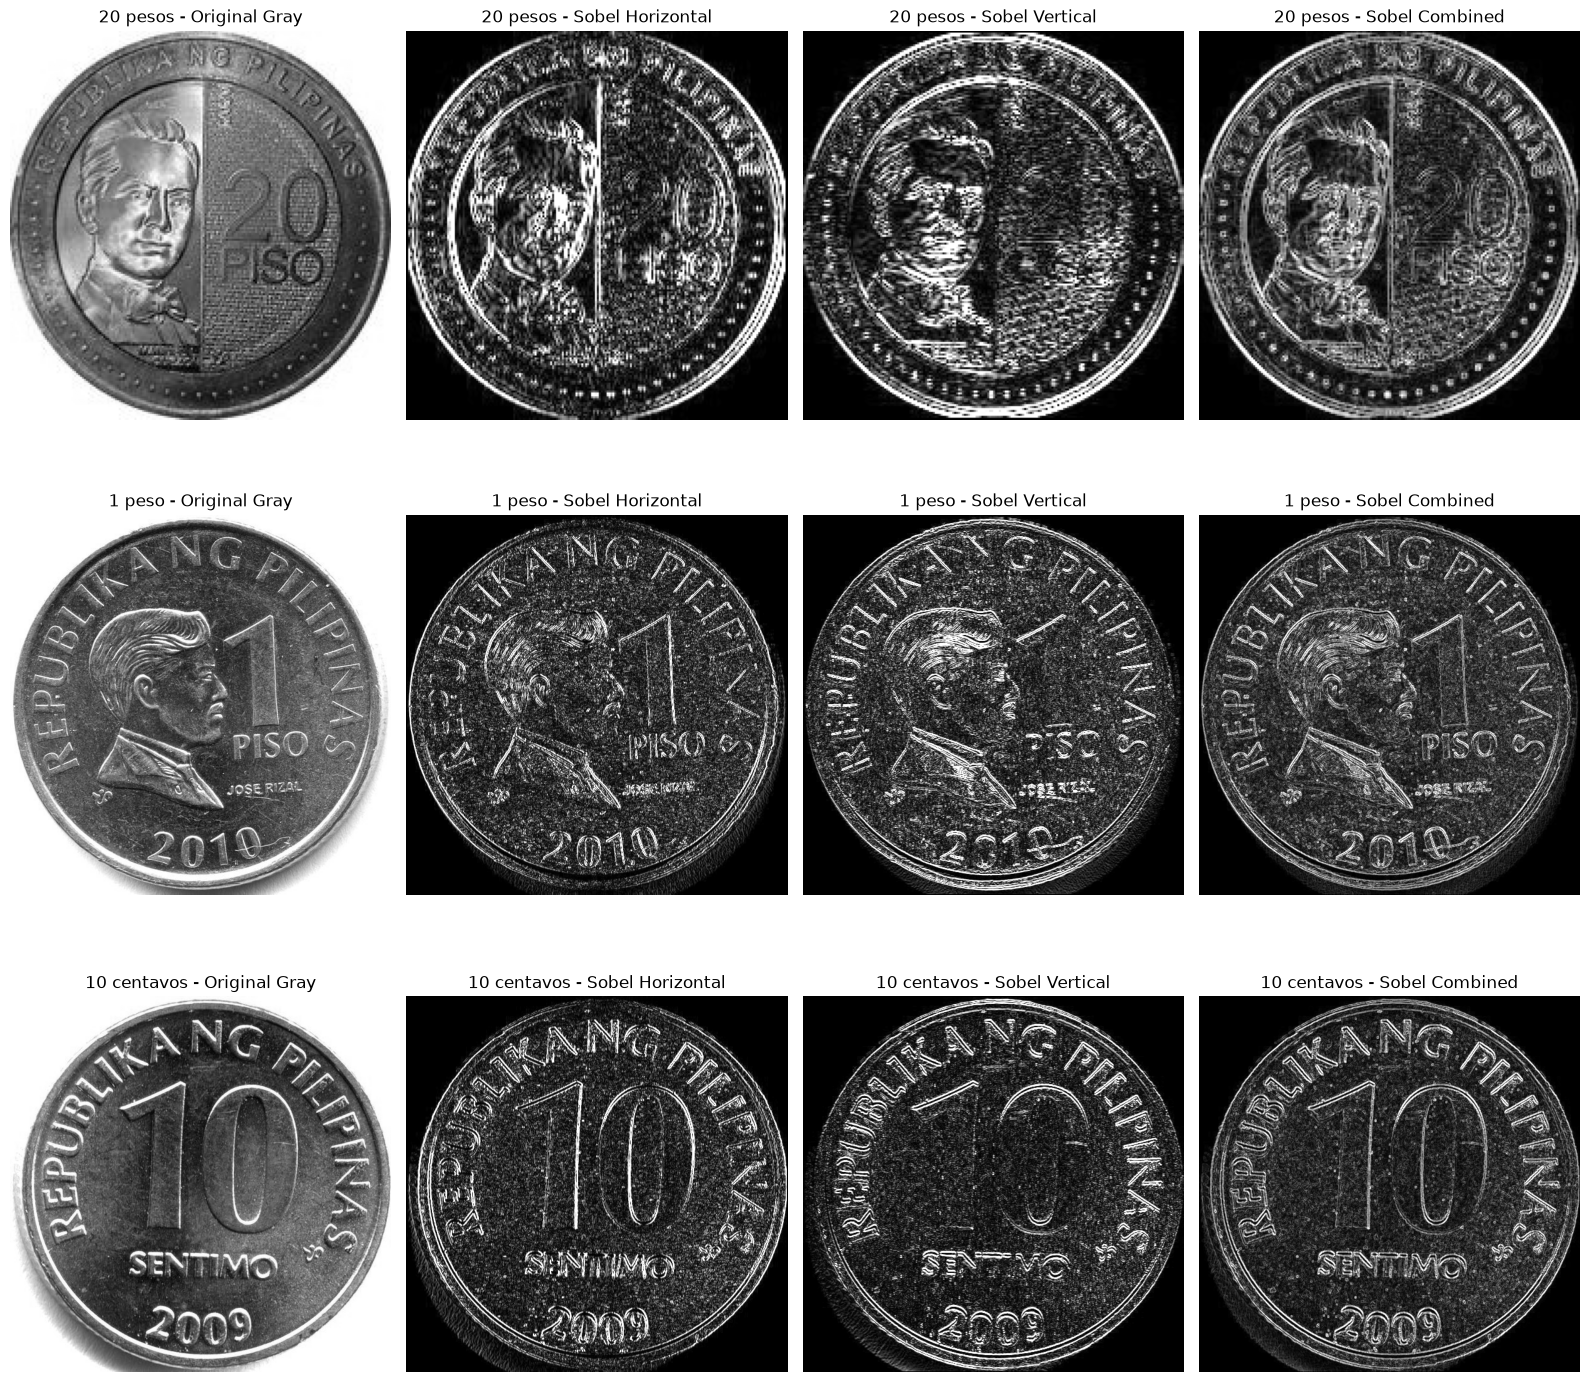

In [40]:
image_folder = Path('coin_images')
selected_images = [
    (image_folder / 'twenty_php.jpg', '20 pesos'),
    (image_folder / 'piso_php.jpeg', '1 peso'),
    (image_folder / 'ten_centavo.jpeg', '10 centavos')
]

fig, axes = plt.subplots(len(selected_images), 4, figsize=(16, 5 * len(selected_images)))

if len(selected_images) == 1:
    axes = np.array([axes])

for row_axes, (image_path, label) in zip(axes, selected_images):
    image = cv2.imread(str(image_path))
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    sobel_x = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=3)
    sobel_y = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=3)

    sobel_x = cv2.convertScaleAbs(sobel_x)
    sobel_y = cv2.convertScaleAbs(sobel_y)
    sobel_combined = cv2.addWeighted(sobel_x, 0.5, sobel_y, 0.5, 0)

    row_axes[0].imshow(gray, cmap='gray')
    row_axes[0].set_title(f'{label} - Original Gray')
    row_axes[0].axis('off')

    row_axes[1].imshow(sobel_x, cmap='gray')
    row_axes[1].set_title(f'{label} - Sobel Horizontal')
    row_axes[1].axis('off')

    row_axes[2].imshow(sobel_y, cmap='gray')
    row_axes[2].set_title(f'{label} - Sobel Vertical')
    row_axes[2].axis('off')

    row_axes[3].imshow(sobel_combined, cmap='gray')
    row_axes[3].set_title(f'{label} - Sobel Combined')
    row_axes[3].axis('off')

plt.tight_layout()
plt.show()

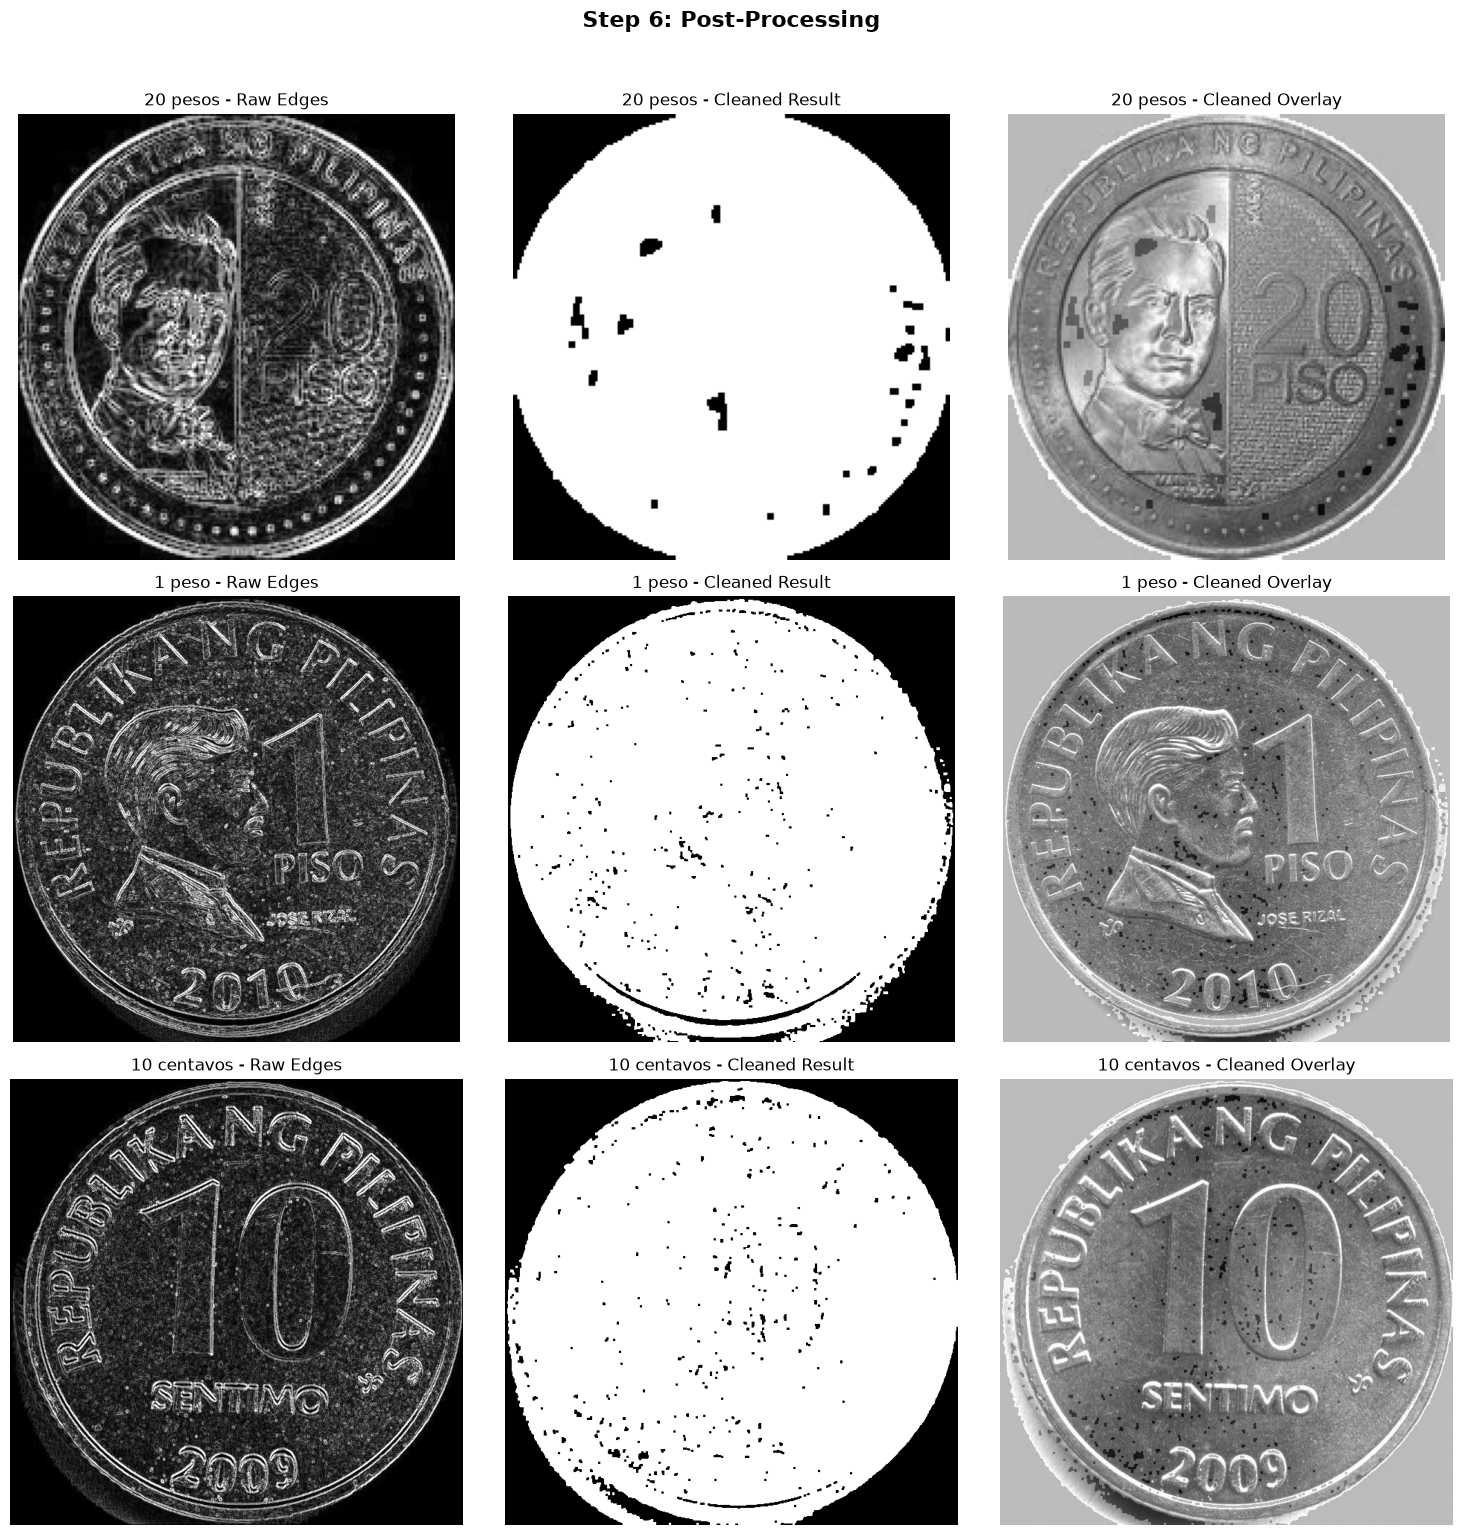

In [44]:
image_folder = Path('coin_images')
selected_images = [
    (image_folder / 'twenty_php.jpg', '20 pesos'),
    (image_folder / 'piso_php.jpeg', '1 peso'),
    (image_folder / 'ten_centavo.jpeg', '10 centavos')
]

cleaned_images = []
for image_path, label in selected_images:
    image = cv2.imread(str(image_path))
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    sobel_x = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=3)
    sobel_y = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=3)
    sobel_x = cv2.convertScaleAbs(sobel_x)
    sobel_y = cv2.convertScaleAbs(sobel_y)
    sobel_combined = cv2.addWeighted(sobel_x, 0.5, sobel_y, 0.5, 0)

    smoothed = cv2.medianBlur(sobel_combined, 3)
    normalized = cv2.normalize(smoothed, None, 0, 255, cv2.NORM_MINMAX)
    enhanced = cv2.equalizeHist(normalized)
    _, binary = cv2.threshold(enhanced, 30, 255, cv2.THRESH_BINARY)

    kernel = np.ones((3, 3), np.uint8)
    cleaned = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, kernel, iterations=1)
    cleaned = cv2.morphologyEx(cleaned, cv2.MORPH_OPEN, kernel, iterations=1)

    overlay = cv2.addWeighted(gray, 0.75, cleaned, 0.25, 0)
    cleaned_images.append((label, sobel_combined, cleaned, overlay))

# Display the raw edge map, cleaned edge map, and overlay for verification
fig, axes = plt.subplots(len(cleaned_images), 3, figsize=(15, 5 * len(cleaned_images)))

if len(cleaned_images) == 1:
    axes = np.array([axes])

for row_axes, (label, raw_edges, cleaned, overlay) in zip(axes, cleaned_images):
    row_axes[0].imshow(raw_edges, cmap='gray')
    row_axes[0].set_title(f'{label} - Raw Edges')
    row_axes[0].axis('off')

    row_axes[1].imshow(cleaned, cmap='gray')
    row_axes[1].set_title(f'{label} - Cleaned Result')
    row_axes[1].axis('off')

    row_axes[2].imshow(overlay, cmap='gray')
    row_axes[2].set_title(f'{label} - Cleaned Overlay')
    row_axes[2].axis('off')

plt.suptitle('Step 6: Post-Processing', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

## SHORT EXPLANATION FOR EVERY RESULT

**Kernel used.** In this code, a 3x3 sharpening kernel was used because it strengthens the contrast between nearby pixels. It is a great help for the details and markings of the coing to stand out more clearly before edge detection.

**Convolution process.** In this part, the kernel was moved across the preprocessed coin image one position at a time. Each location, the surrounding pixel values were multiplied by the kernel and summed to create a sharpened output image.

**Edge detection method.** In this code cell, the applied processing technique waas sobel edge detection in order to sharpened the image  for highlighting a strong intensity changes in horizontal and vertical directions. This made the circular coin boundary and engraved details easier to identify.

**How the result was improved.** It was improved though the cleaned edge map using smoothing, normalization, thresholding, and morphology. It reduces noise, kept the circular outline clearer, and preserved visible coin markings for verification.